# UCS420 Assignment 8: NLP using Python - II
**Name:** Sangam Sangwan | **Roll No:** 1024170388

---
### Q1: Text Preprocessing, Tokenization & Frequency Distribution

/home/a87k/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-2w45ppkm because there was an issue with the default path (/home/a87k/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Sentences: ['AI is changing the world fast.', 'Self-driving cars use computer vision on streets.', 'Machine learning detects diseases in hospitals.', 'However, ethics and privacy remain big challenges.', 'Scientists are working on safe AI systems.', 'The future depends on innovation and safety.']

Words: ['ai', 'is', 'changing', 'the', 'world', 'fast', 'selfdriving', 'cars', 'use', 'computer', 'vision', 'on', 'streets', 'machine', 'learning', 'detects', 'diseases', 'in', 'hospitals', 'however', 'ethics', 'and', 'privacy', 'remain', 'big', 'challenges', 'scientists', 'are', 'working', 'on', 'safe', 'ai', 'systems', 'the', 'future', 'depends', 'on', 'innovation', 'and', 'safety']
split(): ['AI', 'is', 'changing', 'the', 'world']
word_tokenize(): ['AI', 'is', 'changing', 'the', 'world']

Filtered: ['ai', 'changing', 'world', 'fast', 'selfdriving', 'cars', 'use', 'computer', 'vision', 'streets', 'machine', 'learning', 'detects', 'diseases', 'hospitals', 'however', 'ethics', 'privacy', 'rem

<Axes: xlabel='Samples', ylabel='Counts'>

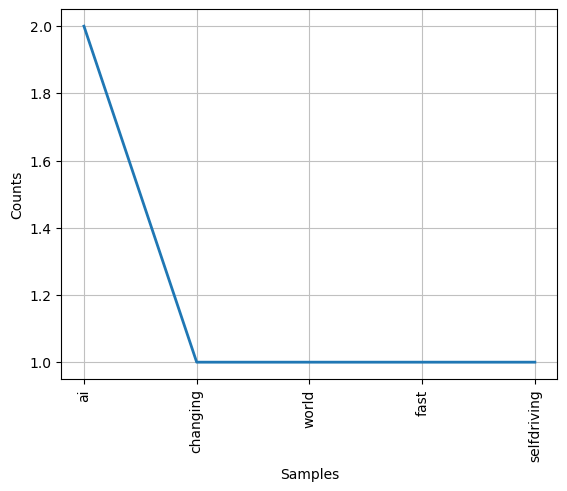

In [1]:
import re, nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# 5-6 sentence paragraph
text = "AI is changing the world fast. Self-driving cars use computer vision on streets. Machine learning detects diseases in hospitals. However, ethics and privacy remain big challenges. Scientists are working on safe AI systems. The future depends on innovation and safety."

# 1. Lowercase & remove punctuation
clean = re.sub(r'[^\w\s]', '', text.lower())

# 2. Tokenize sentences and words
print("Sentences:", sent_tokenize(text))
words = word_tokenize(clean)
print("\nWords:", words)

# 3. Compare split() vs word_tokenize()
print("split():", text.split()[:5])
print("word_tokenize():", word_tokenize(text)[:5])
# Difference: split() keeps punctuation attached to words; word_tokenize() isolates punctuation as separate tokens.

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered = [w for w in words if w not in stop_words]
print("\nFiltered:", filtered)

# 5. Frequency distribution
freq = FreqDist(filtered)
print("\nTop Words:", freq.most_common(5))
freq.plot(5)

---
### Q2: Regex Extraction, Stemming vs Lemmatization

In [2]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import pandas as pd

# 1. Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'[a-zA-Z]+', text.lower())
print("Extracted Alphabet Words:", alpha_words[:8])

# 2. Remove stopwords using NLTK stopwords list
stop_words = set(stopwords.words('english'))
words_clean = [w for w in alpha_words if w not in stop_words]

# 3. Stemming with PorterStemmer
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in words_clean]

# 4. Lemmatization with WordNetLemmatizer
wnl = WordNetLemmatizer()
lemmatized = [wnl.lemmatize(w) for w in words_clean]

# 5. Compare stemmed and lemmatized outputs
df = pd.DataFrame({'Word': words_clean, 'Stemmed': stemmed, 'Lemmatized': lemmatized})
print("\n--- Stemming vs Lemmatization Comparison (Sample) ---")
print(df.drop_duplicates().head(10).to_string(index=False))

print("\n--- When to Prefer Which ---")
print("• Stemming: Fast, heuristic-based chopping (often produces non-words like 'comput', 'chang'). Prefer for large-scale search indexing where speed is paramount.")
print("• Lemmatization: Slower, dictionary-based (preserves true linguistic words like 'computer'). Prefer for sentiment analysis, chatbots, and translation where grammatical validity matters.")

Extracted Alphabet Words: ['ai', 'is', 'changing', 'the', 'world', 'fast', 'self', 'driving']



--- Stemming vs Lemmatization Comparison (Sample) ---
    Word Stemmed Lemmatized
      ai      ai         ai
changing   chang   changing
   world   world      world
    fast    fast       fast
    self    self       self
 driving   drive    driving
    cars     car        car
     use     use        use
computer  comput   computer
  vision  vision     vision

--- When to Prefer Which ---
• Stemming: Fast, heuristic-based chopping (often produces non-words like 'comput', 'chang'). Prefer for large-scale search indexing where speed is paramount.
• Lemmatization: Slower, dictionary-based (preserves true linguistic words like 'computer'). Prefer for sentiment analysis, chatbots, and translation where grammatical validity matters.


---
### Q3: Bag of Words (BoW) & TF-IDF Keyword Extraction

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np
import pandas as pd

# 3 short texts (technology headlines)
texts = [
    "Electric vehicles offer sustainable green transportation with advanced battery technology.",
    "Quantum computing solves complex optimization problems faster than classical computers.",
    "Renewable solar energy reduces carbon emissions and powers smart electric grids."
]

# 1. Bag of Words (CountVectorizer)
cv = CountVectorizer(stop_words='english')
bow_matrix = cv.fit_transform(texts)
print("--- 1. Bag of Words Matrix ---")
print(pd.DataFrame(bow_matrix.toarray(), columns=cv.get_feature_names_out(), index=['Doc 1', 'Doc 2', 'Doc 3']))

# 2. TF-IDF Representation
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(texts)
features = np.array(tfidf_vec.get_feature_names_out())
print("\n--- 2. TF-IDF Matrix (Rounded) ---")
print(pd.DataFrame(tfidf_matrix.toarray().round(2), columns=features, index=['Doc 1', 'Doc 2', 'Doc 3']))

# 3. Top 3 Keywords per text using TF-IDF scores
print("\n--- 3. Top 3 Keywords per Text ---")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_idx = np.argsort(row)[-3:][::-1]
    top_words = [(features[j], round(float(row[j]), 2)) for j in top_idx]
    print(f"Doc {i+1}: {texts[i]}")
    print(f"   Top Keywords: {top_words}\n")

print("Interpretation: High TF-IDF scores identify distinctive domain keywords per document while filtering out generic terms.")

--- 1. Bag of Words Matrix ---
       advanced  battery  carbon  classical  complex  computers  computing  \
Doc 1         1        1       0          0        0          0          0   
Doc 2         0        0       0          1        1          1          1   
Doc 3         0        0       1          0        0          0          0   

       electric  emissions  energy  ...  quantum  reduces  renewable  smart  \
Doc 1         1          0       0  ...        0        0          0      0   
Doc 2         0          0       0  ...        1        0          0      0   
Doc 3         1          1       1  ...        0        1          1      1   

       solar  solves  sustainable  technology  transportation  vehicles  
Doc 1      0       0            1           1               1         1  
Doc 2      0       1            0           0               0         0  
Doc 3      1       0            0           0               0         0  

[3 rows x 27 columns]

--- 2. TF-IDF Matri

---
### Q4: Text Similarity (Jaccard vs Cosine Similarity)

In [4]:
import re
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two short paragraphs on different technologies (AI vs Blockchain)
ai_text = (
    "Artificial intelligence enables machines to learn patterns from vast amounts of data. "
    "It powers neural networks, computer vision, and natural language processing applications. "
    "AI models optimize decision-making and automate repetitive industrial workflows. "
    "Continuous training on large datasets enhances predictive accuracy over time."
)

blockchain_text = (
    "Blockchain technology provides a decentralized and immutable ledger for secure transactions. "
    "It uses cryptographic hashing and consensus mechanisms across distributed network nodes. "
    "Smart contracts automate digital agreements without requiring trusted intermediaries. "
    "This architecture ensures high transparency and tamper-resistant record keeping."
)

# 1. Preprocess and tokenize
stop_words = set(stopwords.words('english'))
tokens_ai = [w for w in re.findall(r'[a-zA-Z]+', ai_text.lower()) if w not in stop_words]
tokens_bc = [w for w in re.findall(r'[a-zA-Z]+', blockchain_text.lower()) if w not in stop_words]

print("AI Tokens (first 6):", tokens_ai[:6])
print("Blockchain Tokens (first 6):", tokens_bc[:6])

# 2a. Jaccard Similarity using sets
set_ai, set_bc = set(tokens_ai), set(tokens_bc)
common_words = set_ai.intersection(set_bc)
total_words = set_ai.union(set_bc)
jaccard_sim = len(common_words) / len(total_words) if total_words else 0.0

print(f"\n--- 2a. Jaccard Similarity ---")
print("Common Words:", common_words)
print(f"Jaccard Score: {jaccard_sim:.4f}")

# 2b. Cosine Similarity using TF-IDF + cosine_similarity()
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform([ai_text, blockchain_text])
cos_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print(f"\n--- 2b. Cosine Similarity ---")
print(f"Cosine Score: {cos_sim:.4f}")

# 2c. Metric Analysis
print("\n--- 2c. Metric Analysis ---")
print("• Jaccard Similarity: Set-theoretic overlap (|A ∩ B| / |A ∪ B|). It only checks binary word presence, ignoring word frequency and corpus importance.")
print("• Cosine Similarity: Geometric angle between TF-IDF feature vectors. It accounts for term frequency, corpus rarity, and document length.")
print("• Conclusion: Cosine Similarity provides better insights because it captures continuous semantic distance in high-dimensional feature space rather than naive word overlaps.")

AI Tokens (first 6): ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'patterns']
Blockchain Tokens (first 6): ['blockchain', 'technology', 'provides', 'decentralized', 'immutable', 'ledger']

--- 2a. Jaccard Similarity ---
Common Words: {'automate'}
Jaccard Score: 0.0147

--- 2b. Cosine Similarity ---
Cosine Score: 0.0154

--- 2c. Metric Analysis ---
• Jaccard Similarity: Set-theoretic overlap (|A ∩ B| / |A ∪ B|). It only checks binary word presence, ignoring word frequency and corpus importance.
• Cosine Similarity: Geometric angle between TF-IDF feature vectors. It accounts for term frequency, corpus rarity, and document length.
• Conclusion: Cosine Similarity provides better insights because it captures continuous semantic distance in high-dimensional feature space rather than naive word overlaps.


---
### Q5: Sentiment Analysis & Word Cloud

--- 1 & 2. Sentiment Analysis & Classification ---
                                                                                    Review  Polarity  Subjectivity Sentiment
The battery life is exceptional and the display quality is absolutely stunning and bright.      0.62          0.93  Positive
  Customer service was terrible, delayed my order, and the item arrived completely broken.     -0.70          0.70  Negative
    The laptop arrived on Tuesday and has standard specifications according to the manual.      0.00          0.00   Neutral
Great performance, sleek design, and very comfortable keyboard for daily programming work.      0.44          0.58  Positive


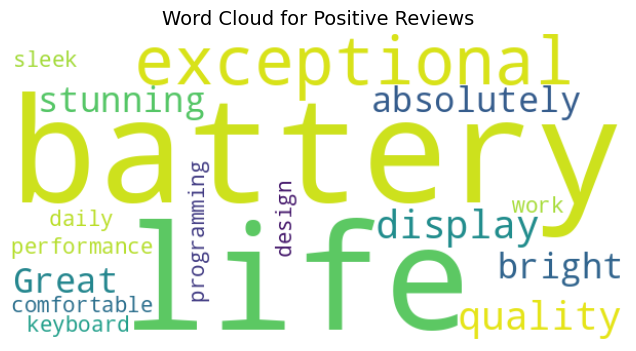

In [5]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd

# Sample product and service reviews
reviews = [
    "The battery life is exceptional and the display quality is absolutely stunning and bright.",
    "Customer service was terrible, delayed my order, and the item arrived completely broken.",
    "The laptop arrived on Tuesday and has standard specifications according to the manual.",
    "Great performance, sleek design, and very comfortable keyboard for daily programming work."
]

# 1 & 2. Polarity, Subjectivity & Classification
results = []
positive_reviews = []

for r in reviews:
    blob = TextBlob(r)
    pol = round(blob.sentiment.polarity, 2)
    subj = round(blob.sentiment.subjectivity, 2)
    
    if pol > 0:
        label = "Positive"
        positive_reviews.append(r)
    elif pol < 0:
        label = "Negative"
    else:
        label = "Neutral"
        
    results.append({"Review": r, "Polarity": pol, "Subjectivity": subj, "Sentiment": label})

df_sentiment = pd.DataFrame(results)
print("--- 1 & 2. Sentiment Analysis & Classification ---")
print(df_sentiment.to_string(index=False))

# 3. Word Cloud for all positive reviews
positive_text = " ".join(positive_reviews)
wc = WordCloud(width=600, height=300, background_color="white").generate(positive_text)

plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Positive Reviews", fontsize=14)
plt.show()

---
### Q6: Next-Word Text Generation using Keras LSTM

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

# ~100-word paragraph for training
text = (
    "Machine learning and artificial intelligence are transforming modern computing. "
    "Neural networks process complex patterns from structured and unstructured data. "
    "Deep learning architectures enable speech recognition computer vision and natural language processing. "
    "Autonomous agents learn through iterative training cycles to optimize decisions. "
    "Intelligent systems continue to expand across healthcare finance and transportation. "
    "Future innovation relies on building scalable robust and safe algorithmic models."
)

# 1. Tokenize text using Keras Tokenizer()
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1
print(f"Vocabulary Size: {total_words}")

# 2. Create input sequences (N-grams) and pad them
tokens = tokenizer.texts_to_sequences([text])[0]
input_sequences = []
for i in range(1, len(tokens)):
    input_sequences.append(tokens[:i+1])

max_seq_len = max(len(x) for x in input_sequences)
padded_sequences = np.array(pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre'))

# Split into features X and target label y
X = padded_sequences[:, :-1]
y = to_categorical(padded_sequences[:, -1], num_classes=total_words)

# Build simple LSTM model
model = Sequential([
    Embedding(total_words, 16),
    LSTM(32),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3. Train model
model.fit(X, y, epochs=100, verbose=0)
print("Model training completed (100 epochs).")

# Generate 2-3 lines of text starting from seed word
seed_word = "machine"
generated_text = seed_word
next_words_count = 18

for _ in range(next_words_count):
    token_list = pad_sequences([tokenizer.texts_to_sequences([generated_text])[0]], maxlen=max_seq_len - 1, padding='pre')
    predicted_idx = int(np.argmax(model.predict(token_list, verbose=0)))
    word = tokenizer.index_word.get(predicted_idx, "")
    if not word:
        break
    generated_text += " " + word

print("\n--- Generated Text ---")
print(generated_text)

I0000 00:00:1791949312.038961      35 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791949312.075367      35 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791949314.101911      35 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Vocabulary Size: 57


Model training completed (100 epochs).



--- Generated Text ---
machine learning learning learning learning learning learning learning learning learning learning learning learning learning and and and and and
